# Module 3 – Features and exploratory analysis

From `games_clean` and `reviews_clean` (Module 1), we build:
- `features_static.parquet`: features **known at release** (T = 0);
- `features_T7/T30/T90.parquet`: **early signals**, computed with the reviews of the first T days only.

Then: exploratory analysis (missing values, distributions, outliers, correlations) and leakage audit.

**Nothing** is imputed or scaled here: this is done in the Module 4 pipeline, fitted on the train set only.

In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from config import *

games = pd.read_parquet(PROC_DIR / "games_clean.parquet")
reviews = pd.read_parquet(PROC_DIR / "reviews_clean.parquet")
assert games["app_id"].is_unique
assert (reviews["days"] >= 0).all()  # Module 1 already removed the reviews posted before release

print("Games:", games.shape, "| Reviews:", reviews.shape)

Games: (10000, 14) | Reviews: (6833248, 6)


## 1. Train / val / test split (Module 2)

To keep the frequent tags, we need to know which games are in the **train** set. We take the `split` column of `target.parquet`, produced by Module 2: split by release date, oldest 70% in train, 15% in validation, 15% in test, with no release day shared between two splits. All modules thus use exactly the same split.

In [2]:
split = pd.read_parquet(PROC_DIR / "target.parquet", columns=["app_id", "split"])
games = games.merge(split, on="app_id", how="left")
assert games["split"].notna().all()  # every game has a split

games.groupby("split")["release_date"].agg(["count", "min", "max"]).loc[["train", "val", "test"]]

,count,min,max
split,,,
train,7007,2015-01-01,2020-05-20
val,1499,2020-05-21,2021-03-29
test,1494,2021-03-30,2021-12-31


## 2. Static features (known at release)

| Feature | Computation |
|---|---|
| `log_price` | `log(1 + base price)`: the price is very skewed |
| `is_free` | base price = 0 |
| `win`, `mac`, `linux` | platforms |
| `required_age` | minimum age |
| `n_languages` | number of supported languages |
| `release_month`, `release_weekday` | release month and weekday (0 = Monday) |
| `desc_length` | length of the description, in characters |
| `in_fronkon` | the game is present in FronkonGames; otherwise, all its FronkonGames columns are empty |

Languages are stored as a list written as text: `"['English', 'French']"`. We count the commas: n languages are separated by n − 1 commas. The empty list `"[]"` has no comma but counts 0 languages, so it is fixed separately. The text is not parsed as a Python list (`ast.literal_eval`): some names contain an unescaped apostrophe (`'K'iche'`), which makes 67 lists unreadable. No language name contains a comma, so the count is exact.

No release year: with a split by date, the validation and test years do not exist in the train set. No `dlc_count` either (see the leakage audit, section 5).

In [3]:
static = pd.DataFrame({"app_id": games["app_id"]})
static["log_price"] = np.log1p(games["price_original"])
static["is_free"] = games["price_original"] == 0
static[["win", "mac", "linux"]] = games[["win", "mac", "linux"]]
static["required_age"] = games["required_age"]
static["n_languages"] = games["languages"].str.count(",") + 1  # n languages = n - 1 commas
static.loc[games["languages"] == "[]", "n_languages"] = 0     # empty list: 0 languages, not 1
static["release_month"] = games["release_date"].dt.month
static["release_weekday"] = games["release_date"].dt.day_of_week  # 0 = Monday
static["desc_length"] = games["description"].str.len()
static["in_fronkon"] = games["languages"].notna()

static.head()

,app_id,log_price,is_free,win,mac,linux,required_age,n_languages,release_month,release_weekday,desc_length,in_fronkon
0,323580,2.771964,False,True,True,True,0.0,13.0,9,1,991.0,True
1,552460,3.044046,False,True,False,True,0.0,1.0,4,1,3664.0,True
2,795040,1.095273,False,True,False,False,0.0,1.0,2,4,497.0,True
3,1448780,2.396986,False,True,False,False,0.0,1.0,7,3,1075.0,True
4,1424910,2.396986,False,True,False,False,0.0,1.0,12,3,1529.0,True


### Genres, categories and tags as binary features

A model cannot read a text such as `"Action,Indie,RPG"`. We turn it into **one 0/1 column per possible value**:

| game | genres (text) | `genre_Action` | `genre_Indie` | `genre_RPG` |
|---|---|---|---|---|
| A | `Action,Indie` | 1 | 1 | 0 |
| B | `RPG` | 0 | 0 | 1 |
| C | empty (missing from FronkonGames) | 0 | 0 | 0 |

This is a *multi-hot* encoding: unlike *one-hot*, a game can have **several** 1s on the same row. `str.get_dummies(sep=",")` does exactly this split, and `add_prefix` adds `genre_`, `cat_` or `tag_` to know where each column comes from.

**We only keep the values present in at least 1% of the train games** (`mean() >= 0.01`: the mean of a 0/1 column is the share of games that have this value). Two reasons:
- a tag present on 3 games teaches the model nothing general, it only adds noise and columns;
- the frequency is computed **on the train set only**. Otherwise, the validation and test games would influence the choice of features: that would be data leakage.

A game missing from FronkonGames has 0 everywhere, like a game with no tag at all: `in_fronkon` lets the model tell them apart.

In [4]:
is_train = games["split"] == "train"

for col, prefix in [("genres", "genre_"), ("categories", "cat_"), ("tags", "tag_")]:
    dummies = games[col].str.get_dummies(sep=",").add_prefix(prefix)
    keep = dummies.columns[dummies[is_train].mean() >= 0.01]  # frequency computed on the TRAIN set only
    print(f"{col}: {dummies.shape[1]} distinct values, {len(keep)} kept")
    static = pd.concat([static, dummies[keep]], axis=1)

genres: 26 distinct values, 14 kept
categories: 56 distinct values, 33 kept


tags: 443 distinct values, 167 kept


### Categories added after the game release (leakage)

Steam categories describe features of the game. Some did not exist yet when our games were released, or are only granted **after** a commercial success. They were added later, mostly by the developers of games that are still active, i.e. the ones that do well. They are therefore not known at release.

We spotted them by reading the coefficients of the Module 4 logistic regression: `cat_Remote Play on Tablet` was among the features pushing the most towards success.

| Categories | Why they come after the release |
|---|---|
| `Remote Play Together`, `Remote Play on Phone`, `Remote Play on Tablet`, `Remote Play on TV` | Steam features that appeared around 2019, but present on games released in 2015 |
| `Family Sharing` | recent category, granted afterwards to most games (91% of the 2015 games) |
| `Steam Trading Cards` | since 2017, Valve only enables the cards after a sales threshold: it is a **sign of success**. The older a game, the more time it had to obtain them |
| `Custom Volume Controls`, `Playable without Timed Input`, `Stereo Sound` | accessibility categories recently introduced by Steam, filled in after the release |

With the Module 2 target, on the train set: 66.7% of successes for the games with `Remote Play on Tablet` (vs 12.0% without), and 43% for the games released from 2018 with trading cards (vs 12% without). The next cell shows the effect of the game's age: the share of games that have these categories, by release year.

In [5]:
LATE_CATEGORIES = ["Remote Play Together", "Remote Play on Phone", "Remote Play on Tablet", "Remote Play on TV",
                   "Family Sharing", "Steam Trading Cards",
                   "Custom Volume Controls", "Playable without Timed Input", "Stereo Sound"]
late_cols = ["cat_" + c for c in LATE_CATEGORIES]

# Share of games that have each category, by release year (games present in FronkonGames)
in_fk = static["in_fronkon"]
static.loc[in_fk, late_cols].groupby(games.loc[in_fk, "release_date"].dt.year).mean().T.round(3)

release_date,2015,2016,2017,2018,2019,2020,2021
cat_Remote Play Together,0.105,0.107,0.110,0.094,0.097,0.104,0.071
cat_Remote Play on Phone,0.013,0.022,0.019,0.016,0.033,0.029,0.014
cat_Remote Play on Tablet,0.019,0.023,0.024,0.019,0.042,0.032,0.013
cat_Remote Play on TV,0.061,0.061,0.062,0.048,0.055,0.041,0.026
cat_Family Sharing,0.906,0.860,0.820,0.804,0.776,0.750,0.766
cat_Steam Trading Cards,0.613,0.575,0.384,0.176,0.140,0.112,0.090
cat_Custom Volume Controls,0.022,0.022,0.019,0.012,0.020,0.019,0.021
cat_Playable without Timed Input,0.014,0.019,0.018,0.015,0.014,0.021,0.019
cat_Stereo Sound,0.011,0.018,0.015,0.011,0.010,0.010,0.013


In [6]:
# Remote Play Together is on 10% of the 2015 games, although the feature did not exist: these categories are removed
static = static.drop(columns=late_cols)

static.to_parquet(PROC_DIR / "features_static.parquet", index=False)
print("Saved: features_static.parquet", static.shape)

Saved: features_static.parquet (10000, 217)


In [7]:
# The 10 most frequent tags in the train set (share of games that have them)
tag_cols = [c for c in static.columns if c.startswith("tag_")]
static.loc[is_train, tag_cols].mean().sort_values(ascending=False).head(10)

tag_Indie           0.581276
tag_Adventure       0.354217
tag_Action          0.349079
tag_Casual          0.321678
tag_Singleplayer    0.310975
tag_Simulation      0.190952
tag_Strategy        0.181675
tag_2D              0.168118
tag_RPG             0.154132
tag_Puzzle          0.128158
dtype: float64

## 3. Early signals (T = 7, 30, 90 days)

For each T, we only keep the reviews posted **before T days** (`days < T`), then compute per game:
- `n_reviews`: number of reviews;
- `pos_ratio`: share of positive reviews;
- `has_reviews`: the game has at least one review.

We start from **all the games** (`reindex`): a game with no review before T is kept, with `n_reviews = 0`. Its `pos_ratio` stays **empty** (it is unknown, not 0), and `has_reviews` is False.

T = 0 corresponds to the static features alone: there are no reviews yet.

Two review columns are **not** used, because they are not known at T:
- `helpful`: these are vote counters read when the data was collected, so they contain votes given long after T;
- `hours`: the check below shows that these are the hours read at collection time, not at review time.

### Are the hours played (`hours`) known at T?

A player who posts a review `days` days after the release has played **at most** `24 × (days + 1)` hours since the release. If many reviews are above this limit, `hours` also contains playtime from **after** the review.

In [8]:
early = reviews[reviews["days"] < 30]
impossible = early["hours"] > 24 * (early["days"] + 1)  # more hours than the time elapsed since release

print(f"Reviews of the first 30 days with impossible hours: {impossible.sum()} ({impossible.mean():.1%})")
early[impossible].head()

Reviews of the first 30 days with impossible hours: 131855 (13.6%)


,app_id,date,days,is_recommended,hours,helpful
53,275850,2016-08-14,2,True,149.100006,0
104,275850,2016-08-13,1,True,91.800003,0
146,275850,2016-08-13,1,True,84.599998,4
298,1174180,2019-12-07,2,False,218.199997,0
325,1240440,2021-11-19,4,True,154.000000,3


**Conclusion:** about 13.6% of the reviews of the first 30 days have more hours played than the time elapsed since the release, e.g. 149 hours two days after the release (app 275850). Part of it may come from early access before the official release date, but not such a proportion. `hours` is therefore the playtime **at collection time**: it contains the future of the game. Using the hours as a signal at T would be **data leakage**, so they are not used.

In [9]:
signals_by_T = {}

for T in [t for t in T_VALUES if t > 0]:
    window = reviews[reviews["days"] < T]
    assert window["days"].max() < T  # no review after T

    signals = window.groupby("app_id").agg(
        n_reviews=("is_recommended", "size"),  # number of reviews
        pos_ratio=("is_recommended", "mean"),  # mean of True/False = share of positive reviews
    )
    signals = signals.reindex(games["app_id"]).reset_index()  # all games, even without reviews
    signals["n_reviews"] = signals["n_reviews"].fillna(0).astype(int)
    signals["has_reviews"] = signals["n_reviews"] > 0

    signals.to_parquet(PROC_DIR / f"features_T{T}.parquet", index=False)
    signals_by_T[T] = signals
    print(f"T = {T:>2}: {signals['has_reviews'].mean():.1%} of the games have at least one review")

T =  7: 68.2% of the games have at least one review


T = 30: 72.9% of the games have at least one review


T = 90: 75.8% of the games have at least one review


## 4. Exploratory analysis

We look at the main numerical features, the signals at T = 30 and the target `success` (Module 2).

In [10]:
num_cols = ["log_price", "n_languages", "desc_length", "required_age"]
eda = (games[["app_id", "split"]]
       .merge(static[["app_id"] + num_cols], on="app_id")
       .merge(signals_by_T[30], on="app_id")
       .merge(pd.read_parquet(PROC_DIR / "target.parquet", columns=["app_id", "success"]), on="app_id"))

print("% missing values per split:")
(eda.drop(columns=["app_id", "split"]).isna().groupby(eda["split"]).mean() * 100).round(1)

% missing values per split:


,log_price,n_languages,desc_length,required_age,n_reviews,pos_ratio,has_reviews,success
split,,,,,,,,
test,0.0,23.1,23.2,23.1,0.0,25.9,0.0,0.0
train,0.0,21.6,21.8,21.6,0.0,27.8,0.0,0.0
val,0.0,22.7,22.9,22.7,0.0,25.4,0.0,0.0


**Reading:**
- The FronkonGames columns (`n_languages`, `desc_length`, `required_age`) are empty for about 22% of the games: these are the games missing from FronkonGames. This rate is almost the same in the three splits (21.6% to 23.2%), so these missing values do not depend on the release date. `desc_length` has 12 more empty games: they are in FronkonGames, but without a description.
- `pos_ratio` is empty for the games with no review before T = 30: 27.8% of the train games, 25.4% in validation and 25.9% in test. Recent games get a first review quickly a bit more often. This slight change over time remains small.
- `success` has no missing value: a game without reviews is a failure, not missing data (Module 2).
- No value is imputed here: imputation is done in the Module 4 pipeline, fitted on the train set.

In [11]:
eda.drop(columns="app_id").describe().T

,count,mean,std,min,25%,50%,75%,max
log_price,10000.0,1.689141,1.102319,0.0,0.688135,1.790091,2.484073,5.602082
n_languages,7797.0,4.961395,10.592536,0.0,1.000000,1.000000,6.000000,103.000000
desc_length,7785.0,1358.004753,1254.956296,8.0,701.000000,1108.000000,1688.000000,67520.000000
required_age,7797.0,0.263306,2.059107,0.0,0.000000,0.000000,0.000000,18.000000
n_reviews,10000.0,97.283800,948.335153,0.0,0.000000,5.000000,17.000000,47984.000000
pos_ratio,7285.0,0.813553,0.243414,0.0,0.722222,0.905660,1.000000,1.000000


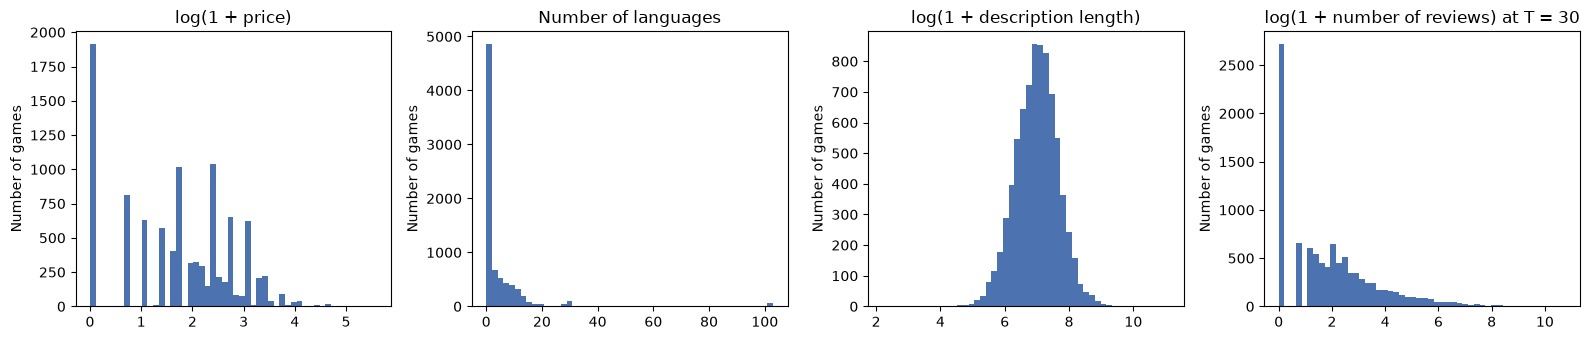

In [12]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
plots = {  # log(1 + x) for very skewed features, otherwise only one bar is visible
    "log(1 + price)": eda["log_price"],
    "Number of languages": eda["n_languages"],
    "log(1 + description length)": np.log1p(eda["desc_length"]),
    "log(1 + number of reviews) at T = 30": np.log1p(eda["n_reviews"]),
}
for ax, (title, values) in zip(axes, plots.items()):
    ax.hist(values.dropna(), bins=50, color="#4C72B0")
    ax.set_title(title)
    ax.set_ylabel("Number of games")
plt.tight_layout()
plt.show()

**Distributions and outliers:**
- **Price:** 19% of the games are free (the bar at 0). The other prices are grouped on "round" values (0.99; 4.99; 9.99; 19.99…), hence the separate bars. The maximum is 269.99.
- **Languages:** most games have 1 language (median = 1). 65 games declare **103 languages**, whereas the next ones have at most 71: they are mostly small casual games (*Chocolate makes you happy 7*, *Spooky Mahjong*…) that tick every language offered by Steam. These are not reading errors, but an unreliable declaration.
- **Description:** median of about 1,100 characters, maximum 67,520. Without the log, all the values are squeezed to the left by these few very long descriptions.
- **Reviews at T = 30:** very skewed. Median of 5 reviews, maximum of 47,984, and about 27% of the games at 0.

None of these values is removed: they are real games, and removing them would bias the sample. The log transform reduces their weight for linear models, and tree-based models are not sensitive to them. For Module 4: `desc_length` and `n_reviews` should be log-transformed before the logistic regression.

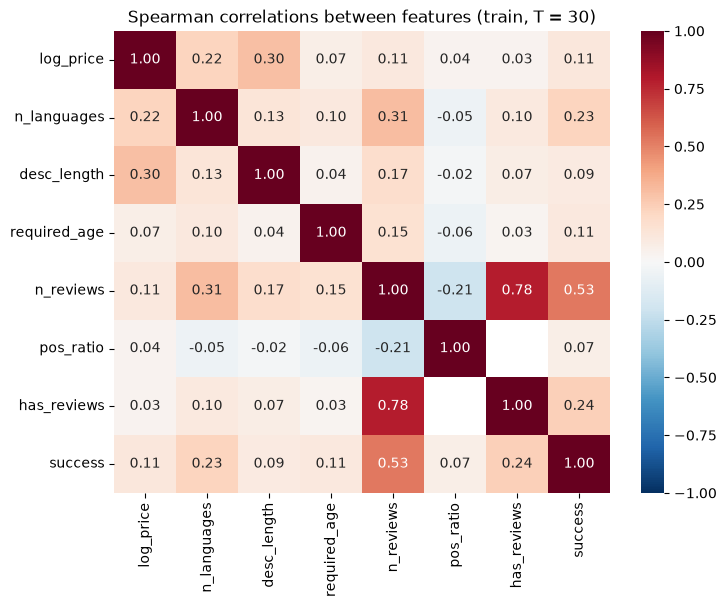

In [13]:
# Spearman correlation (computed on the ranks): not very sensitive to extreme values,
# unlike Pearson, which would be dominated by the few games with 40,000 reviews.
# Computed on the train set only.
corr = eda[eda["split"] == "train"].drop(columns=["app_id", "split"]).corr(method="spearman")

plt.figure(figsize=(8, 6))
sns.heatmap(corr, cmap="RdBu_r", vmin=-1, vmax=1, center=0, annot=True, fmt=".2f")
plt.title("Spearman correlations between features (train, T = 30)")
plt.show()

**Reading:**
- **Link with the target `success`** (last row): the number of reviews at T = 30 is by far the most linked to success (0.53). Then come `has_reviews` (0.24) and, among the features known at release, the **number of languages** (0.23). Price, required age and description length are weakly linked (0.09 to 0.11). This explains why the models are much better from T = 7 (Module 4).
- `pos_ratio` at T = 30 is hardly linked to success (0.07), although success requires ≥ 80% positive reviews. This is because it is **negatively** correlated with `n_reviews` (−0.21): with 1 or 2 reviews, the ratio is often 0 or 1 (100%), and it gets closer to the mean as reviews accumulate. A `pos_ratio` computed on few reviews is unreliable: it must always be read together with `n_reviews`.
- No pair of features is almost redundant, except `n_reviews` and `has_reviews` (0.78), which is expected: `has_reviews` is simply `n_reviews > 0`.
- The `pos_ratio` × `has_reviews` cell is empty: `pos_ratio` only exists when `has_reviews` is true, so `has_reviews` is constant on these rows and the correlation cannot be computed.
- A correlation is not a causal relationship: many languages may simply signal a bigger publisher.

## 5. Leakage audit

A feature is allowed only if its value is **known at prediction time** (at release for T = 0, at T days for the early signals).

| Column | Decision | Reason |
|---|---|---|
| `rating`, `positive_ratio`, `user_reviews` (Kozyriev) | excluded (Module 1) | measured after release, and they almost define the target |
| `price_final`, `discount` (Kozyriev), `Price` (FronkonGames) | excluded (Module 1) | price and discount at collection time, not at launch |
| `steam_deck` | excluded (Module 1) | compatibility tested after the Steam Deck release (2022) |
| `Estimated owners`, `Peak CCU`, `Positive`, `Negative`, `Recommendations`, `User score`, `Metacritic score`, playtime (FronkonGames) | not loaded (Module 1) | measured after release |
| `dlc_count` | **excluded** | the number of DLCs grows after release, especially for games that do well: reverse causality |
| release year | **excluded** | split by date: the validation and test years do not exist in the train set |
| `helpful` (reviews) | **excluded** | votes accumulated until data collection, so after T |
| `hours` (reviews) | **excluded** | playtime read at collection time: 13.6% of the reviews of the first 30 days have more hours than the time elapsed since release (section 3) |
| categories `Remote Play` (4), `Family Sharing`, `Steam Trading Cards`, accessibility (3) | **excluded** | added after release: later Steam features, or cards granted after a sales threshold (section 2). Detected thanks to the Module 4 coefficients |
| `tags` | kept, **risk** | tags added by players, sometimes after release; popular games get more of them. We keep their presence (0/1), not their count. To test: model with and without tags |
| other `categories`, `price_original`, `description`, `languages`, `genres` | kept, low risk | values read at collection time: they may have been updated after release, but with no obvious link to success |
| `is_recommended` (reviews) | kept, low risk | a player can change their review later, but it is rare |

## 6. Summary: files produced for Module 4

| File | Content | For which T |
|---|---|---|
| `features_static.parquet` | `app_id` + 11 simple features + 14 genres, 24 categories and 167 tags as 0/1 (217 columns) | all (only file at T = 0) |
| `features_T7.parquet`, `features_T30.parquet`, `features_T90.parquet` | `app_id`, `n_reviews`, `pos_ratio`, `has_reviews` | to join with `features_static` on `app_id` |

The split comes from `target.parquet` (Module 2): the tags kept are chosen on the same train set as the model's.

Key points for Module 4:
- missing values (`pos_ratio`, FronkonGames columns) must be imputed **inside the pipeline**, fitted on the train set;
- `desc_length` and `n_reviews` are very skewed: log-transform them for the logistic regression;
- 9 categories added after release were removed;
- to do later (slot 3): feature selection inside the pipeline, and permutation importance for each T.